# Tropical Cyclones with Neighborhood Filters

A neighborhood reduction aggregates every value within a great-circle radius `r` of the point it's called on.
Several standard tropical cyclone diagnostics can be built from these kinds of operations:

| Diagnostic | Neighborhood expression |
|---|---|
| Storm center | `PS == nb.min(PS)` |
| Pressure deficit | `nb.mean(PS) - PS` |
| Warm-core anomaly | `T - nb.mean(T)` |
| Integrated kinetic energy (IKE) | `nb.sum(ke * area)` |
| Peak wind near the center | `nb.max(wind_speed)` |
| Windy area | `nb.mean(wind_speed >= 17)` on equal-area cells |
| Wind footprint | `nb.max(on_track) > 0` dilates the track by `r` |

For an introduction to the API itself, see the
[Neighborhood Filter](neighborhood-filter.ipynb) user guide.

---

**Part 1** finds and characterizes a real cyclone in a model snapshot.

**Part 2** tracks Hurricane Maria and its neighbors through a 3 km MPAS simulation of
September 2017 on NCAR's HPC systems.

You will need:
* Access to NCAR's Glade file system
* An interactive session, preferably with 64Gb of RAM and 8 cores

Expect the full notebook to take 5–10 minutes.


## Setup:

In [1]:
import os
import tempfile
import urllib.request
from pathlib import Path

# Downloads and caches (tutorial data, coastlines, best tracks) go here.
# e.g. SCRATCH_DIR = Path("/glade/work/<user>/cyclones")
SCRATCH_DIR = Path(tempfile.gettempdir()) / "uxarray-cyclones"
SCRATCH_DIR.mkdir(parents=True, exist_ok=True)

# Read when uxarray is imported, so it is set before the imports below
os.environ["UXARRAY_TUTORIAL_CACHE_DIR"] = str(SCRATCH_DIR / "tutorial")


def fetch(url):
    # Download once into SCRATCH_DIR and reuse the copy; local paths pass through
    if "://" not in str(url):
        return Path(url)
    path = SCRATCH_DIR / "downloads" / str(url).rsplit("/", 1)[-1]
    if not path.exists():
        path.parent.mkdir(exist_ok=True)
        urllib.request.urlretrieve(url, path)
    return path

<img src='data:image/png;base64,iVBORw0KGgoAAAANSUhEUgAAAEAAAABACAYAAACqaXHeAAAABHNCSVQICAgIfAhkiAAAAAlwSFlz
AAAB+wAAAfsBxc2miwAAABl0RVh0U29mdHdhcmUAd3d3Lmlua3NjYXBlLm9yZ5vuPBoAAA6zSURB
VHic7ZtpeFRVmsf/5966taWqUlUJ2UioBBJiIBAwCZtog9IOgjqACsogKtqirT2ttt069nQ/zDzt
tI4+CrJIREFaFgWhBXpUNhHZQoKBkIUASchWla1S+3ar7r1nPkDaCAnZKoQP/D7mnPOe9/xy76n3
nFSAW9ziFoPFNED2LLK5wcyBDObkb8ZkxuaoSYlI6ZcOKq1eWFdedqNzGHQBk9RMEwFAASkk0Xw3
ETacDNi2vtvc7L0ROdw0AjoSotQVkKSvHQz/wRO1lScGModBFbDMaNRN1A4tUBCS3lk7BWhQkgpD
lG4852/+7DWr1R3uHAZVQDsbh6ZPN7CyxUrCzJMRouusj0ipRwD2uKm0Zn5d2dFwzX1TCGhnmdGo
G62Nna+isiUqhkzuKrkQaJlPEv5mFl2fvGg2t/VnzkEV8F5ioioOEWkLG86fvbpthynjdhXYZziQ
x1hC9J2NFyi8vCTt91Fh04KGip0AaG9zuCk2wQCVyoNU3Hjezee9bq92duzzTmxsRJoy+jEZZZYo
GTKJ6SJngdJqAfRzpze0+jHreUtPc7gpBLQnIYK6BYp/uGhw9YK688eu7v95ysgshcg9qSLMo3JC
4jqLKQFBgdKDPoQ+Pltb8dUyQLpeDjeVgI6EgLIQFT5tEl3rn2losHVsexbZ3EyT9wE1uGdkIPcy
BGxn8QUq1QrA5nqW5i2tLqvrrM9NK6AdkVIvL9E9bZL/oyfMVd/jqvc8LylzRBKDJSzIExwhQzuL
QYGQj4rHfFTc8mUdu3E7yoLtbTe9gI4EqVgVkug2i5+uXGo919ixbRog+3fTbQ8qJe4ZOYNfMoTI
OoshUNosgO60AisX15aeI2PSIp5KiFLI9ubb1vV3Qb2ltwLakUCDAkWX7/nHKRmmGIl9VgYsUhJm
2NXjKYADtM1ygne9QQDIXlk49FBstMKx66D1v4+XuQr7vqTe0VcBHQlRWiOCbmmSYe2SqtL6q5rJ
zsTb7lKx3FKOYC4DoqyS/B5bvLPxvD9Qtf6saxYLQGJErmDOdOMr/zo96km1nElr8bmPOBwI9COv
HnFPRIwmkSOv9kcAS4heRsidOkpeWBgZM+UBrTFAXNYL5Vf2ii9c1trNzpYdaoVil3WIc+wdk+gQ
noie3ecCcxt9ITcLAPWt/laGEO/9U6PmzZkenTtsSMQ8uYywJVW+grCstAvCIaAdArAsIWkRDDs/
KzLm2YcjY1Lv0UdW73HabE9n6V66cxSzfEmuJssTpKGVp+0vHq73FwL46eOjpMpbRAnNmJFrGJNu
Ukf9Yrz+3rghiumCKNXXWPhLYcjxGsIpoCMsIRoFITkW8AuyM8jC1+/QLx4bozCEJIq38+1rtpR6
V/yzb8eBlRb3fo5l783N0CWolAzJHaVNzkrTzlEp2bQ2q3TC5gn6wpnoQAmwSiGh2GitnTmVMc5O
UyfKWUKCIsU7+fZDKwqdT6DDpvkzAX4/+AMFjk0tDp5GRXLpQ2MUmhgDp5gxQT8+Y7hyPsMi8uxF
71H0oebujHALECjFKaW9Lm68n18wXp2kVzIcABytD5iXFzg+WVXkegpAsOOYziqo0OkK76GyquC3
ltZAzMhhqlSNmmWTE5T6e3IN05ITFLM4GdN0vtZ3ob8Jh1NAKXFbm5PtLU/eqTSlGjkNAJjdgn/N
aedXa0tdi7+t9G0FIF49rtMSEgAs1kDLkTPO7ebm4IUWeyh1bKomXqlgMG6kJmHcSM0clYLJ8XtR
1GTnbV3F6I5wCGikAb402npp1h1s7LQUZZSMIfALFOuL3UUrfnS8+rez7v9qcold5tilgHbO1fjK
9ubb17u9oshxzMiUBKXWqJNxd+fqb0tLVs4lILFnK71H0Ind7uiPgACVcFJlrb0tV6DzxqqTIhUM
CwDf1/rrVhTa33/3pGPxJYdQ2l2cbgVcQSosdx8uqnDtbGjh9SlDVSMNWhlnilfqZk42Th2ZpLpf
xrHec5e815zrr0dfBZSwzkZfqsv+1FS1KUknUwPARVvItfKUY+cn57yP7qv07UE3p8B2uhUwLk09
e0SCOrK+hbdYHYLjRIl71wWzv9jpEoeOHhGRrJAzyEyNiJuUqX0g2sBN5kGK6y2Blp5M3lsB9Qh4
y2Ja6x6+i0ucmKgwMATwhSjdUu49tKrQ/pvN5d53ml2CGwCmJipmKjgmyuaXzNeL2a0AkQ01Th5j
2DktO3Jyk8f9vcOBQHV94OK+fPumJmvQHxJoWkaKWq9Vs+yUsbq0zGT1I4RgeH2b5wef7+c7bl8F
eKgoHVVZa8ZPEORzR6sT1BzDUAD/d9F78e2Tzv99v8D+fLVTqAKAsbGamKey1Mt9Ann4eH3gTXTz
idWtAJ8PQWOk7NzSeQn/OTHDuEikVF1R4z8BQCy+6D1aWRfY0tTGG2OM8rRoPaeIj5ZHzJxszElN
VM8K8JS5WOfv8mzRnQAKoEhmt8gyPM4lU9SmBK1MCQBnW4KONT86v1hZ1PbwSXPw4JWussVjtH9Y
NCoiL9UoH/6PSu8jFrfY2t36erQHXLIEakMi1SydmzB31h3GGXFDFNPaK8Rme9B79Ixrd0WN+1ij
NRQ/doRmuFLBkHSTOm5GruG+pFjFdAmorG4IXH1Qua6ASniclfFtDYt+oUjKipPrCQB7QBQ2lrgP
fFzm+9XWUtcqJ3/5vDLDpJ79XHZk3u8nGZ42qlj1+ydtbxysCezrydp6ugmipNJ7WBPB5tydY0jP
HaVNzs3QzeE4ZpTbI+ZbnSFPbVOw9vsfnVvqWnirPyCNGD08IlqtYkh2hjZ5dErEQzoNm+6ykyOt
Lt5/PQEuSRRKo22VkydK+vvS1XEKlhCJAnsqvcVvH7f/ZU2R67eXbMEGAMiIV5oWZWiWvz5Fv2xG
sjqNJQRvn3Rs2lji/lNP19VjAQDgD7FHhujZB9OGqYxRkZxixgRDVlqS6uEOFaJUVu0rPFzctrnF
JqijImVp8dEKVWyUXDk92zAuMZ6bFwpBU1HrOw6AdhQgUooChb0+ItMbWJitSo5Ws3IAOGEOtL53
0vHZih9sC4vtofZ7Qu6523V/fmGcds1TY3V36pUsBwAbSlxnVh2xLfAD/IAIMDf7XYIkNmXfpp2l
18rkAJAy9HKFaIr/qULkeQQKy9zf1JgDB2uaeFNGijo5QsUyacNUUTOnGO42xSnv4oOwpDi1zYkc
efUc3I5Gk6PhyTuVKaOGyLUAYPGIoY9Pu/atL/L92+4q9wbflRJ2Trpm/jPjdBtfnqB/dIThcl8A
KG7hbRuKnb8qsQsVvVlTrwQAQMUlf3kwJI24Z4JhPMtcfng5GcH49GsrxJpGvvHIaeem2ma+KSjQ
lIwUdYyCY8j4dE1KzijNnIP2llF2wcXNnsoapw9XxsgYAl6k+KzUXbi2yP3KR2ecf6z3BFsBICdW
nvnIaG3eHybqX7vbpEqUMT+9OL4Qpe8VON7dXuFd39v19FoAABRVePbGGuXTszO0P7tu6lghUonE
llRdrhArLvmKdh9u29jcFiRRkfLUxBiFNiqSU9icoZQHo5mYBI1MBgBH6wMNb+U7Pnw337H4gi1Y
ciWs+uks3Z9fztUvfzxTm9Ne8XXkvQLHNytOOZeiD4e0PgkAIAYCYknKUNUDSXEKzdWNpnil7r4p
xqkjTarZMtk/K8TQ6Qve78qqvXurGwIJqcOUKfUWHsm8KGvxSP68YudXq4pcj39X49uOK2X142O0
Tz5/u/7TVybqH0rSya6ZBwD21/gubbrgWdDgEOx9W
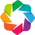

In [2]:
import cartopy
import cartopy.crs as ccrs
import geoviews as gv
import holoviews as hv
import numpy as np
import pandas as pd
import xarray as xr
from bokeh.models import CustomJSTickFormatter

import uxarray as ux

# Load the plotting extension
hv.extension("bokeh")
cartopy.config["data_dir"] = str(SCRATCH_DIR / "cartopy")  # coastline downloads

R_EARTH = 6.371e6  # m


def degree_ticks(positive, negative):
    # Axis labels such as 65.00°W and 18.50°N
    return CustomJSTickFormatter(
        code=f"return Math.abs(tick).toFixed(2) + '°' + "
        f"(tick > 0 ? '{positive}' : tick < 0 ? '{negative}' : '')"
    )


def map_axes():
    # Longitude and latitude tick labels for a map; fresh formatters for every plot
    return dict(xformatter=degree_ticks("E", "W"), yformatter=degree_ticks("N", "S"))


# Map layers declare that their coordinates are longitude and latitude (PlateCarree), and
# maps are drawn in PlateCarree too, so GeoViews keeps every layer in degrees
lonlat = ccrs.PlateCarree()


# Indexing helper
def at(field, n_face):
    return xr.DataArray(field).isel(n_face=n_face)

## Part 1: A Cyclone in a Model Snapshot

`ne120-tcsubset` is a regional subset of a ~25 km cubed-sphere simulation with a
tropical cyclone off northwest Australia.

In [3]:
ds = ux.tutorial.open_dataset("ne120-tcsubset")
grid = ds.uxgrid
lat, lon = grid.face_lat.values, grid.face_lon.values
ds

<xarray.UxDataset> Size: 301kB
Dimensions:  (n_face: 1417, plev: 26)
Coordinates:
  * plev     (plev) float64 208B 354.5 738.9 1.397e+03 ... 9.706e+04 9.926e+04
    time     object 8B ...
Dimensions without coordinates: n_face
Data variables:
    PS       (n_face) float32 6kB ...
    T        (plev, n_face) float32 147kB ...
    Z3       (plev, n_face) float32 147kB ...

In [4]:
ps_plot = (
    (ds["PS"] / 100)
    .plot.polygons(
        cmap="viridis",
        clabel="PS (hPa)",
        title="Surface pressure",
        width=500,
        height=450,
    )
    .opts(**map_axes())
)
ps_plot

:Image   [x,y]   (x_y PS)

### Build the neighborhood once

The expensive part of a neighborhood reduction is finding the neighbors. Building it
with `Grid.neighborhood` returns a neighborhood object, which can be reused for multiple aggregations.

This is a regional grid, so neighborhoods near the boundary are cut off. `n_neighbors` shows the edge effects:

In [5]:
# One neighbor search per radius, reused below
nb = {r: grid.neighborhood(r=r) for r in (0.5, 1.0, 2.0)}
nb[1.0]

<Neighborhood on='face centers' r=1.0 n_elements=1417 neighbors_per_element=[24, 63]>

In [6]:
counts = nb[1.0].n_neighbors
interior = counts >= 0.8 * counts.median()

ux.UxDataArray(counts, uxgrid=grid).plot.polygons(
    cmap="cividis",
    title="Cells within 1° (edge cells are truncated)",
    width=500,
    height=450,
).opts(**map_axes())

:Image   [x,y]   (x_y n_neighbors)

### Find the center

A cell is a local minimum if it equals the minimum of its own neighborhood.

In [7]:
ps = ds["PS"]
is_min = (ps == nb[1.0].min(ps)) & interior

center = int(np.flatnonzero(is_min.values)[0])
print(f"local minima away from the edge: {int(is_min.sum())}")
print(
    f"center: {-lat[center]:.2f}°S, {lon[center]:.2f}°E, PS = {ps.values[center] / 100:.1f} hPa"
)

(
    ps_plot
    * hv.Points([(lon[center], lat[center])]).opts(color="red", marker="x", size=14)
).opts(**map_axes())

local minima away from the edge: 1
center: 17.66°S, 114.54°E, PS = 968.5 hPa


:Overlay
   .Image.I  :Image   [x,y]   (x_y PS)
   .Points.I :Points   [x,y]

### How deep is the low?

The pressure deficit is the central pressure relative to its environment. Measured against larger neighborhoods, the same low
looks deeper, so a tracking threshold needs a radius.

In [8]:
for neighborhood in nb.values():
    depth = neighborhood.mean(ps) - ps
    print(f"r = {neighborhood.r}°: deficit {depth.values[center] / 100:5.1f} hPa")

r = 0.5°: deficit   8.2 hPa
r = 1.0°: deficit  19.4 hPa
r = 2.0°: deficit  32.4 hPa


### Is it warm-core?

Tropical cyclones have a warm core aloft. Subtracting each level's 2° neighborhood
mean temperature removes the large-scale environment and leaves the local anomaly. The
neighborhood can be reused through all 26 pressure levels.

In [9]:
t_anom = ds["T"] - nb[2.0].mean(ds["T"])

profile = at(t_anom, center).sel(plev=slice(10000, None))  # surface to 100 hPa
profile_plot = hv.Curve(
    (profile.values, profile.plev.values / 100), "T anomaly (K)", "Pressure (hPa)"
).opts(invert_yaxis=True, width=300, height=450, title="Above the center")

map_400 = (
    t_anom.sel(plev=40000, method="nearest")
    .plot.polygons(
        cmap="RdBu_r",
        symmetric=True,
        clabel="K",
        title="T anomaly near 400 hPa",
        width=500,
        height=450,
    )
    .opts(**map_axes())
)
profile_plot + map_400

:Layout
   .Curve.I :Curve   [T anomaly (K)]   (Pressure (hPa))
   .Image.I :Image   [x,y]   (x_y T)

The anomaly peaks near 370 hPa, about 8 K warmer than its surroundings. Together,
the local minimum, the pressure deficit, and the warm core are the usual criteria
for telling a tropical cyclone apart from other lows.

## Part 2: Tracking Hurricane Maria's Cumulative Energy

The NSF NCAR Mesoamerica Affinity Group (MAAG) ran MPAS-Atmosphere over
15–30 September 2017 on a limited-area, variable-resolution mesh 
that is 3 km over the western Atlantic basin, and 15 km elsewhere
([GDEX dataset d010077](https://gdex.ucar.edu/datasets/d010077/)). 

Hourly surface fields are analyzed on the native mesh. The model's version of Hurricane Maria forms within the run and stays
in the 3 km region until the run ends. Hurricanes Jose and Lee are active in the region as well.

This section tracks every tropical cyclone in the run and computes IKE, peak wind
and gale-force radius along each track, then
compares the model's Maria with the National Hurricane Center's best track.

### Aggregation with neighborhood filters

A neighborhood filter computes its reduction at every cell. That cost grows with the
number of cells times the cells per neighborhood, and at 3 km a 3° neighborhood holds
about 45,000 cells. Over this region, it amounts to roughly $10^{10}$ cell pairs per hour. 

Instead, we can be clever about how to aggregate the important data, so that we avoid 
incurring computational costs. 

The strategy:

| Pass | Where | Radius | Tool |
|---|---|---|---|
| 1. Pressure minima | every 3 km cell | 0.25° (~300 cells) | `Neighborhood.min` |
| 2. Windy area, pressure rise, warm core | every 12 km cell | 2° | `Neighborhood.mean` |
| 3. Link fixes in time | each fix | 1° per hour | nearest fix |
| IKE, peak wind, gale-force area, footprint | every 12 km cell | 2–3° | `Neighborhood.sum`, `.max` |

Pass 1 needs the 3 km mesh, since a storm center is only as precise as its cell.
Everything else is a sum, maximum or average over a disk of 2–3°, which a 12 km copy of
the fields gives just as well, as long as the 3 km values are aggregated without loss.

---

### Setup:

In [10]:
import glob
import os
import time as clock

import dask
from dask.distributed import Client, LocalCluster, as_completed

# Use the cores this job was allocated, not every core on the node
n_cores = (
    len(os.sched_getaffinity(0)) if hasattr(os, "sched_getaffinity") else os.cpu_count()
)
dask.config.set(scheduler="threads", num_workers=n_cores)

maag_dirs = [  # GDEX d010077 native-mesh output on GLADE (current and former layout)
    "/glade/campaign/collections/gdex/data/d010077/native_diag",
    "/glade/campaign/collections/rda/data/d010077/native_diag",
]
maag_dir = os.environ.get("MAAG_DIR") or next(
    (d for d in maag_dirs if os.path.isdir(d)), None
)
if maag_dir is None:
    raise FileNotFoundError(
        "MAAG output not found. This section runs on NCAR's GLADE file system; "
        "set MAAG_DIR to use a copy elsewhere."
    )
static_file = f"{maag_dir}/MAAG.static.nc"
HOURS = slice(None)  # all 361 hours; e.g. slice(96, 168) for a quicker first run
diag_files = sorted(glob.glob(f"{maag_dir}/diag.2017-09-*.nc"))[HOURS]

# Degrees. Covers Maria from its formation near 12°N (centers need R_DISK of clearance
# from the edge), and Jose until it moves north of about 38°N
REGION = dict(lon=(-83, -53), lat=(5, 40))
R_MIN = 0.25  # pass 1: lowest pressure within this radius
R_DISK = 2.0  # pass 2: tests over the disk within this radius, eye included
HEALPIX_ZOOM = 9  # the copy for pass 2 and IKE: HEALPix cells about 12.7 km across
WINDY_AREA = (
    0.3  # pass 2: least fraction of the disk's area with wind of 17 m/s or more
)
PRESSURE_RISE = (
    300  # pass 2: least excess of the disk's mean pressure over the center's, Pa
)
WARM_CORE = (
    1.0  # pass 2: least excess of the center's 250 hPa temperature over the disk's, K
)
R_IKE = 3.0  # IKE, gale-force area and the footprint
LINK_SPEED, MAX_GAP, MIN_HOURS = 1.0, 3, 24  # degrees per hour, hours, hours
N_READERS = min(n_cores, 16)  # processes reading the hourly files

# NHC best tracks ("b-decks") of the storms active in the run
BDECKS = {
    name: f"https://ftp.nhc.noaa.gov/atcf/archive/2017/bal{number}2017.dat.gz"
    for name, number in [("JOSE", 12), ("LEE", 14), ("MARIA", 15)]
}
timings = {}
print(f"{len(diag_files)} hourly files; {n_cores} cores")

361 hourly files; 6 cores


---

### The mesh and the hourly fields

The mesh is cropped to the track region by face centers. A pool of separate processes reads the hourly files; each
returns only the region's values for its hour, which go straight into arrays here, and
those become a UxDataset on the cropped grid. (Opening the files as one dask-backed
UxDataset and calling `compute()` would assemble the whole region on a single worker
first, more memory than one worker gets.) The dask dashboard link shows the readers at
work.

In [11]:
start = clock.perf_counter()
mesh = ux.open_grid(static_file)
in_region = (
    (mesh.face_lon >= REGION["lon"][0])
    & (mesh.face_lon <= REGION["lon"][1])
    & (mesh.face_lat >= REGION["lat"][0])
    & (mesh.face_lat <= REGION["lat"][1])
)
cells = np.flatnonzero(in_region.values)
timings["read mesh"] = clock.perf_counter() - start
print(f"{mesh.n_face:,} cells in the mesh, {cells.size:,} in the region")

6,087,575 cells in the mesh, 1,458,377 in the region


In [12]:
def read_hour(path, cells):
    # Pressure, 10 m wind speed and 250 hPa temperature in the region, from one hourly file
    with xr.open_dataset(path) as ds:
        mslp, u10, v10, t250 = (
            ds[v].values[0][cells] for v in ["mslp", "u10", "v10", "temperature_250hPa"]
        )
    return mslp, np.hypot(u10, v10), t250


start = clock.perf_counter()
maag_time = np.array(
    [np.datetime64(os.path.basename(f)[5:18].replace("_", "T")) for f in diag_files]
)
units = {"mslp": "Pa", "wind_speed": "m/s", "temperature_250hPa": "K"}
fields = {
    name: np.empty((len(diag_files), cells.size), dtype="float32") for name in units
}
print(f"holding {sum(a.nbytes for a in fields.values()) / 1e9:.1f} GB of hourly fields")

# The HDF5 library behind netCDF4 isn't thread-safe, so separate processes read the files
# in parallel.
with (
    LocalCluster(
        n_workers=N_READERS, threads_per_worker=1, dashboard_address=":0"
    ) as cluster,
    Client(cluster) as client,
):
    print("dask dashboard:", client.dashboard_link)
    futures = client.map(
        read_hour, diag_files, cells=client.scatter(cells, broadcast=True)
    )
    hour = {f.key: i for i, f in enumerate(futures)}
    for future, values in as_completed(futures, with_results=True):
        for array, value in zip(fields.values(), values):
            array[hour[future.key]] = value
        future.release()

region = mesh.isel(n_face=cells)  # the grid cropped to the same cells
storm = ux.UxDataset(
    {
        name: (("time", "n_face"), a, {"units": units[name]})
        for name, a in fields.items()
    },
    coords={"time": maag_time},
    uxgrid=region,
)
msl, wind, warm = storm["mslp"], storm["wind_speed"], storm["temperature_250hPa"]
del mesh, fields  # the full 6.09M-cell mesh is no longer needed
lat_r, lon_r = region.face_lat.values, region.face_lon.values
area_r = region.face_areas.values * R_EARTH**2  # m²
spacing = np.sqrt(area_r / (np.sqrt(3) / 2)) / 1e3  # hexagon center spacing, km
timings["read hourly fields"] = clock.perf_counter() - start
print(
    f"{msl.sizes['time']} hours x {region.n_face:,} cells; "
    f"spacing {np.percentile(spacing, 1):.1f}–{np.percentile(spacing, 99):.1f} km"
)

holding 6.3 GB of hourly fields
dask dashboard: https://jupyterhub.hpc.ucar.edu/stable/user/cdupuis/proxy/44399/status
361 hours x 1,458,377 cells; spacing 2.9–3.2 km


### Pass 1: pressure minima everywhere

A cell is a candidate center if it has the lowest pressure within 0.25° and is below
1008 hPa. The radius is kept small because this is the one pass over every cell; it
lets through many small, convective lows, which pass 2 removes cheaply. Chunking
along time spreads the hours over the cores and bounds the memory of the results.

In [13]:
start = clock.perf_counter()
nb_min = region.neighborhood(r=R_MIN)
msl_chunked = msl.chunk(time=4)  # one task per 4 hours
is_min = (msl_chunked == nb_min.min(msl_chunked)) & (msl_chunked <= 100800)
cand_t, cand_k = np.nonzero(is_min.values)
timings["pass 1: pressure minima"] = clock.perf_counter() - start
print(nb_min)
print(
    f"{cand_t.size:,} candidate centers ({cand_t.size / msl.sizes['time']:.0f} per hour)"
)

<Neighborhood on='face centers' r=0.25 n_elements=1458377 neighbors_per_element=[68, 386]>
25,673 candidate centers (71 per hour)


### A 12 km copy of the fields

Each 3 km cell is assigned to its nearest cell of a HEALPix grid at zoom 9 (about 12.7 km),
and each HEALPix cell keeps what the large-radius filters need, without loss: the sum of
its kinetic energy and gale-force area, its strongest wind, and its area-weighted mean
pressure, 250 hPa temperature and windy fraction. HEALPix cells all have the same area,
so a plain neighborhood mean over them is area-weighted. A 3° neighborhood then holds
about 2,200 cells rather than 45,000, so filtering the whole region every hour is
affordable.

In [14]:
start = clock.perf_counter()
tree = region.get_ball_tree(
    coordinates="face centers",
    coordinate_system="spherical",
    distance_metric="haversine",
)


def clear_of_edges(k, margin):
    # True where a disk of `margin` degrees around cell k lies inside the region
    dlon = margin / np.cos(np.radians(np.abs(lat_r[k]) + margin))
    return (
        (lat_r[k] - margin >= REGION["lat"][0])
        & (lat_r[k] + margin <= REGION["lat"][1])
        & (lon_r[k] - dlon >= REGION["lon"][0])
        & (lon_r[k] + dlon <= REGION["lon"][1])
    )


hp = ux.Grid.from_healpix(zoom=HEALPIX_ZOOM)
in_box = (
    (hp.face_lon >= REGION["lon"][0])
    & (hp.face_lon <= REGION["lon"][1])
    & (hp.face_lat >= REGION["lat"][0])
    & (hp.face_lat <= REGION["lat"][1])
)
coarse = hp.isel(n_face=np.flatnonzero(in_box.values))
lat_c, lon_c = coarse.face_lat.values, coarse.face_lon.values

# Each 3 km cell belongs to its nearest HEALPix cell
owner = (
    coarse.get_ball_tree(
        coordinates="face centers",
        coordinate_system="spherical",
        distance_metric="haversine",
    )
    .query(np.c_[lon_r, lat_r], k=1, return_distance=False)
    .ravel()
)
owned_area = np.bincount(owner, weights=area_r, minlength=coarse.n_face)
has_cells = owned_area > 0
order = np.argsort(owner, kind="stable")
starts = np.searchsorted(owner[order], np.flatnonzero(has_cells))
# Where the mesh is coarser than the copy, a HEALPix cell may own no cell of the mesh; it
# takes the nearest cell's value for maxima and means (sums are unaffected)
empty = ~has_cells
nearest = (
    tree.query(np.c_[lon_c[empty], lat_c[empty]], k=1, return_distance=False).ravel()
    if empty.any()
    else np.empty(0, dtype=int)
)


def to_coarse(hourly, how):
    # Aggregate the 3 km values hourly(t) onto the HEALPix cells for every hour: an
    # area-weighted "sum" or "mean", or the "max"
    out = np.empty((msl.sizes["time"], coarse.n_face), dtype="float32")
    for t in range(out.shape[0]):
        v = np.asarray(hourly(t), dtype="float32")
        if how == "max":
            out[t, has_cells] = np.maximum.reduceat(v[order], starts)
        else:
            total = np.bincount(owner, weights=v * area_r, minlength=coarse.n_face)
            out[t] = (
                total if how == "sum" else total / np.where(has_cells, owned_area, 1)
            )
        if how != "sum":
            out[t, empty] = v[nearest]
    return ux.UxDataArray(out, dims=["time", "n_face"], uxgrid=coarse)


w, p, t250 = wind.values, msl.values, warm.values
pressure_c = to_coarse(lambda t: p[t], "mean")
warm_c = to_coarse(lambda t: t250[t], "mean")
windy_c = to_coarse(lambda t: w[t] >= 17, "mean")  # fraction of area with ≥ 17 m/s
gale_c = to_coarse(lambda t: w[t] >= 17.5, "sum")  # gale-force area, m²
ke_c = to_coarse(  # ½ρ|u|²·h·dA (ρ = 1 kg/m³, h = 1 m), J
    lambda t: np.where(w[t] >= 18, 0.5 * 1.0 * w[t] ** 2, 0), "sum"
)
wind_c = to_coarse(lambda t: w[t], "max")
timings["12 km copy"] = clock.perf_counter() - start
print(
    f"{coarse.n_face:,} HEALPix cells, {has_cells.mean():.0%} of them holding mesh cells"
)

72,804 HEALPix cells, 100% of them holding mesh cells


### Pass 2: is the minimum a tropical cyclone?

For each candidate low, over the disk within 2° (about 220 km),

- at least 30% of the disk's area has wind of 17 m/s or more: a broad windy area
  rather than a narrow band along a front;
- the disk's mean pressure is at least 3 hPa above the center's, a stand-in for a
  closed isobar;
- the center's 250 hPa temperature is at least 1 K above the disk's mean: a warm core
  aloft. In this run that separates tropical cyclones (about +5 K) from midlatitude
  and heat lows (within 0.6 K); at 500 hPa those lows are also 1–3 K warm.

They are computed for every cell of the 12 km copy and read at each candidate's cell.

The thresholds are `WINDY_AREA`,
`PRESSURE_RISE` and `WARM_CORE` in the configuration cell at the top of this part.

In [15]:
start = clock.perf_counter()
nb_disk = coarse.neighborhood(r=R_DISK)
cand_c = owner[cand_k]  # the HEALPix cell each candidate lies in
tests = pd.DataFrame(
    {
        "windy_area": nb_disk.mean(windy_c).values[cand_t, cand_c],
        "pressure_rise": nb_disk.mean(pressure_c).values[cand_t, cand_c]
        - msl.values[cand_t, cand_k],
        "warm_core": warm.values[cand_t, cand_k]
        - nb_disk.mean(warm_c).values[cand_t, cand_c],
    }
)
passed = (
    (tests.windy_area >= WINDY_AREA)
    & (tests.pressure_rise >= PRESSURE_RISE)
    & (tests.warm_core >= WARM_CORE)
    & clear_of_edges(cand_k, R_DISK)
).values
fix_t, fix_k = cand_t[passed], cand_k[passed]
timings["pass 2: disk tests"] = clock.perf_counter() - start
print(nb_disk)
print(f"{passed.sum():,} of {cand_t.size:,} candidates pass")

<Neighborhood on='face centers' r=2.0 n_elements=72804 neighbors_per_element=[251, 971]>
384 of 25,673 candidates pass


### Pass 3: link fixes into tracks

A storm moves well under 1° in an hour, and two tropical cyclones are essentially
never that close, so each track simply takes the nearest fix within 1° per elapsed
hour. A track may go undetected for up to 3 hours (crossing land, for example), and
only tracks lasting at least a day are kept.

In [16]:
def great_circle(lat1, lon1, lat2, lon2):
    # Great-circle distance in degrees (haversine)
    p1, p2 = np.radians(lat1), np.radians(lat2)
    a = (
        np.sin((p2 - p1) / 2) ** 2
        + np.cos(p1) * np.cos(p2) * np.sin(np.radians(lon2 - lon1) / 2) ** 2
    )
    return np.degrees(2 * np.arcsin(np.sqrt(a)))


n_hours = msl.sizes["time"]
by_hour = np.split(fix_k, np.searchsorted(fix_t, np.arange(1, n_hours)))
finished, active = [], []
for t, found in enumerate(by_hour):
    unused, still_active = list(found), []
    for track in sorted(active, key=len, reverse=True):  # longest tracks pick first
        last_t, last_k = track[-1]
        if t - last_t > MAX_GAP:
            finished.append(track)
            continue
        if unused:
            dist = great_circle(
                lat_r[last_k], lon_r[last_k], lat_r[unused], lon_r[unused]
            )
            j = int(np.argmin(dist))
            if dist[j] <= LINK_SPEED * (t - last_t):
                track.append((t, unused.pop(j)))
        still_active.append(track)
    active = still_active + [[(t, k)] for k in unused]

tracks = [
    np.array(tr) for tr in finished + active if tr[-1][0] - tr[0][0] + 1 >= MIN_HOURS
]
print(f"{len(tracks)} tracks lasting at least {MIN_HOURS} h")

2 tracks lasting at least 24 h


### Following each storm before and after its tropical stage

Weak TCs and TCs undergoing extratropical transition are harder to detect with simple 
methods. Once a low has been tropical, its track is followed backward from the
first fix and forward from the last through pressure minima that pass the pass-2
tests at half strength (15% windy area, 1.5 hPa pressure rise, 0.5 K warm core), with
the same linking rules. Pass 2 already computed the tests for every pass-1 minimum, 
so following a track adds no filtering, only a quick search over minima already found. 
It can only reach minima that pass 1 kept, though, which are below 1008 hPa.

In [17]:
from collections import defaultdict

relaxed = (
    (tests.windy_area >= WINDY_AREA / 2)
    & (tests.pressure_rise >= PRESSURE_RISE / 2)
    & (tests.warm_core >= WARM_CORE / 2)
    & clear_of_edges(cand_k, R_DISK)
).values
in_a_track = {(t, k) for track in tracks for t, k in track}
pool = defaultdict(list)  # hour -> relaxed candidates not yet in a track
for t, k in zip(cand_t[relaxed], cand_k[relaxed]):
    if (t, k) not in in_a_track:
        pool[t].append(k)


def follow(t_last, k_last, step):
    # Fixes from the pool that continue a track one hour at a time in direction `step`
    found, t = [], t_last + step
    while 0 <= t < n_hours and abs(t - t_last) <= MAX_GAP:
        if pool[t]:
            dist = great_circle(
                lat_r[k_last], lon_r[k_last], lat_r[pool[t]], lon_r[pool[t]]
            )
            j = int(np.argmin(dist))
            if dist[j] <= LINK_SPEED * abs(t - t_last):
                t_last, k_last = t, pool[t].pop(j)
                found.append((t_last, k_last))
        t += step
    return found


extended, tropical = [], []
for track in tracks:
    before = follow(*track[0], step=-1)[::-1]
    after = follow(*track[-1], step=+1)
    extended.append(np.array(before + [tuple(fix) for fix in track] + after))
    tropical.append(
        np.r_[np.zeros(len(before)), np.ones(len(track)), np.zeros(len(after))] > 0
    )
    print(
        f"track {len(extended) - 1}: {len(before)} h before, {len(track)} h tropical, {len(after)} h after"
    )
tracks = extended

track 0: 0 h before, 108 h tropical, 0 h after
track 1: 9 h before, 261 h tropical, 0 h after


### IKE, peak wind and gale-force radius

ACE (accumulated cyclone energy) sums the square of a TC's peak wind, every
six hours. It cannot tell a compact storm from a large one with the same peak wind.
**Integrated kinetic energy** (IKE; Powell and Reinhold 2007) adds up the kinetic
energy of all tropical-storm-force wind (≥ 18 m/s) around the center, in a layer 1 m
deep at the 10 m level:

$$\mathrm{IKE} = \int_V \tfrac{1}{2} \rho\, |\mathbf{U}|^2 \, dV \approx h \int_A \tfrac{1}{2} \rho\, |\mathbf{u}|^2 \, dA, \qquad h = 1\ \mathrm{m},\ \rho = 1\ \mathrm{kg\,m^{-3}}$$

where $\mathbf{u} = (u_{10}, v_{10})$ is the horizontal wind at 10 m. Because the layer has a
fixed depth, the volume integral is an area integral times $h$. As in Powell and
Reinhold, the vertical wind $w$ is left out, because it's relatively small.

In [18]:
start = clock.perf_counter()
nb_ike = coarse.neighborhood(r=R_IKE)
track_t = np.concatenate([tr[:, 0] for tr in tracks])
track_k = np.concatenate([tr[:, 1] for tr in tracks])
track_c = owner[track_k]
hours = np.unique(track_t)  # only the hours with a storm
row = np.searchsorted(hours, track_t)

ike = nb_ike.sum(ke_c.isel(time=hours)).values[row, track_c] / 1e12  # TJ
gale_area = nb_ike.sum(gale_c.isel(time=hours)).values[row, track_c]  # m²
peak_wind = nb_disk.max(wind_c.isel(time=hours)).values[row, track_c]

# A neighborhood max of a field marking each fix dilates the track by R_IKE
marks = np.zeros((hours.size, coarse.n_face), dtype="float32")
marks[row, track_c] = 1
near_track = (
    nb_ike.max(ux.UxDataArray(marks, dims=["time", "n_face"], uxgrid=coarse)).values > 0
)
footprint = np.full(region.n_face, np.nan, dtype="float32")
for i, t in enumerate(hours):
    footprint = np.fmax(footprint, np.where(near_track[i][owner], w[t], np.nan))

complete = clear_of_edges(track_k, R_IKE)  # the whole 3° disk is inside the region
fixes = pd.DataFrame(
    {
        "track": np.repeat(np.arange(len(tracks)), [len(tr) for tr in tracks]),
        "tropical": np.concatenate(tropical),
        "time": maag_time[track_t],
        "lat": lat_r[track_k],
        "lon": lon_r[track_k],
        "pressure (hPa)": msl.values[track_t, track_k] / 100,
        "peak wind (m/s)": peak_wind,
        "IKE (TJ)": np.where(complete, ike, np.nan),
        "gale radius (km)": np.where(
            complete, np.sqrt(gale_area / np.pi) / 1e3, np.nan
        ),
    }
)
timings["IKE, peak wind, gale radius"] = clock.perf_counter() - start
fixes

,track,tropical,time,lat,lon,pressure (hPa),peak wind (m/s),IKE (TJ),gale radius (km)
0,0,True,2017-09-15 01:00:00,25.623919,-67.433441,987.377686,39.659775,11.929990,137.517878
1,0,True,2017-09-15 02:00:00,25.566906,-67.843842,983.596313,44.027084,13.845421,143.270894
2,0,True,2017-09-15 03:00:00,25.603790,-67.913605,981.757874,42.665607,14.976045,147.480553
3,0,True,2017-09-15 04:00:00,25.635773,-67.954224,983.103821,47.081833,15.494884,153.519842
4,0,True,2017-09-15 06:00:00,25.734032,-68.240021,982.897095,43.747543,14.220851,146.005766
...,...,...,...,...,...,...,...,...,...
373,1,True,2017-09-29 08:00:00,33.432049,-60.846283,979.379639,39.978096,26.305515,209.225317
374,1,True,2017-09-29 09:00:00,33.595169,-60.644043,980.341736,36.423359,24.858876,205.031348
375,1,True,2017-09-29 10:00:00,33.709625,-60.453339,981.605286,35.082844,25.381071,207.186266
376,1,True,2017-09-29 11:00:00,33.844696,-60.239960,983.224304,29.666124,24.809749,208.482775


### Labelling storm tracks

Each track is named after the NHC best track closest to it, by median distance at
the times they share, if that is within 4°. The model's storms drift from the real ones over two weeks, so the threshold
is generous; tracks with no match are other tropical lows.

In [19]:
def read_bdeck(source):
    # One row per synoptic time: position, intensity and 34 kt wind radii (nautical miles)
    cols = ["basin", "number", "when", "technum", "tech", "tau", "lat", "lon", "vmax",
            "mslp", "type", "rad", "windcode", "r_ne", "r_se", "r_sw", "r_nw"]  # fmt: skip
    deck = pd.read_csv(
        source,
        header=None,
        names=cols,
        usecols=range(17),
        dtype=str,
        skipinitialspace=True,
    )
    deck = deck[deck.rad.isin(["34", "0"]) | deck.rad.isna()].drop_duplicates("when")
    hemi = lambda s, neg: (
        np.where(s.str[-1] == neg, -1, 1) * s.str[:-1].astype(float) / 10
    )  # noqa: E731
    return pd.DataFrame(
        {
            "time": pd.to_datetime(deck.when.str.strip(), format="%Y%m%d%H"),
            "lat": hemi(deck.lat.str.strip(), "S"),
            "lon": hemi(deck.lon.str.strip(), "W"),
            "peak wind (m/s)": deck.vmax.astype(float) * 0.5144,
            "pressure (hPa)": deck.mslp.astype(float),
            "type": deck.type.str.strip(),
        }
        | {
            # Radius of a disk with the area of the four quadrants' 34 kt extents
            "gale radius (km)": np.sqrt(
                (
                    deck[["r_ne", "r_se", "r_sw", "r_nw"]].astype(float).fillna(0) ** 2
                ).mean(axis=1)
            ).values
            * 1.852
        }
    )


best = {}
for name, source in BDECKS.items():
    try:
        best[name] = read_bdeck(fetch(source))
    except Exception as err:  # no internet access, for example
        print(f"{name} best track unavailable ({type(err).__name__})")


def name_of(track):
    # The best track closest to this one, by median distance over their shared times
    distances = {}
    for name, obs in best.items():
        shared = track.merge(obs, on="time", suffixes=("", "_obs"))
        if len(shared):
            distances[name] = np.median(
                great_circle(shared.lat, shared.lon, shared.lat_obs, shared.lon_obs)
            )
    closest = min(distances, key=distances.get, default=None)
    return closest if closest and distances[closest] <= 4 else None


names = fixes.groupby("track")[["time", "lat", "lon"]].apply(name_of)
fixes["name"] = fixes.track.map(names)
print(
    fixes.groupby("track").agg(
        name=("name", "first"), start=("time", "min"), hours=("time", "size")
    )
)

        name               start  hours
track                                  
0       JOSE 2017-09-15 01:00:00    108
1      MARIA 2017-09-17 22:00:00    270


### The model's Maria at its peak

The 3 km wind field around the deepest fix, with the edge of the pass-2 disk and
coastlines in red. The 10 m wind drops over the islands and, in blocky patches, over the
water just around them. Those patches most likely come from the run's surface input (sea
surface temperatures on a 0.25° grid near the coast), not from the storm.

In [20]:
def circle(lat0, lon0, r, n=181):
    # Points r degrees of great circle from (lat0, lon0)
    b, d = np.radians(np.linspace(0, 360, n)), np.radians(r)
    p0, l0 = np.radians(lat0), np.radians(lon0)
    p = np.arcsin(np.sin(p0) * np.cos(d) + np.cos(p0) * np.sin(d) * np.cos(b))
    lam = l0 + np.arctan2(
        np.sin(b) * np.sin(d) * np.cos(p0), np.cos(d) - np.sin(p0) * np.sin(p)
    )
    return np.column_stack([np.degrees(lam), np.degrees(p)])


is_maria = fixes.name == "MARIA"
# Without best tracks to name it, take the longest track
longest = fixes.track == fixes.track.value_counts().idxmax()
maria = fixes[is_maria] if is_maria.any() else fixes[longest]
peak = maria.loc[maria["pressure (hPa)"].idxmin()]
t_peak, k_peak = track_t[peak.name], track_k[peak.name]  # rows of `fixes` follow these
near = np.flatnonzero(great_circle(lat_r[k_peak], lon_r[k_peak], lat_r, lon_r) <= 2.5)
snapshot = ux.UxDataArray(
    wind.values[t_peak, near],
    dims=["n_face"],
    uxgrid=region.isel(n_face=near),
    name="wind_speed",
)
print(
    f"{peak.time}: {peak['pressure (hPa)']:.0f} hPa, peak wind {peak['peak wind (m/s)']:.0f} m/s"
)
(
    snapshot.plot.polygons(
        projection=lonlat,
        cmap="viridis",
        clabel="10 m wind (m/s)",
        title=f"Model Maria, {peak.time:%d %b %H}Z",
        frame_width=550,
        data_aspect=1,
    )
    * gv.feature.coastline.opts(scale="10m", line_color="red", line_width=1)
    * gv.feature.borders.opts(scale="10m", line_color="red", line_width=0.5)
    * gv.Path([circle(peak.lat, peak.lon, R_DISK)], crs=lonlat).opts(
        color="white", line_dash="dashed"
    )
).opts(projection=lonlat, **map_axes())

2017-09-20 23:00:00: 937 hPa, peak wind 58 m/s


:Overlay
   .Image.I     :Image   [Longitude,Latitude]   (Longitude_Latitude wind_speed)
   .Coastline.I :Feature   [Longitude,Latitude]
   .Borders.I   :Feature   [Longitude,Latitude]
   .Path.I      :Path   [Longitude,Latitude]

### The warm core at the peak

The pass-2 warm-core test at the same hour: each 12 km cell's 250 hPa temperature minus
its 2° neighborhood mean (`nb_disk.mean`). Pass-1 pressure minima are gray dots, and the
ones that pass all of pass 2 are lime crosses.

In [21]:
warm_anomaly = warm_c.isel(time=t_peak) - nb_disk.mean(warm_c.isel(time=[t_peak])).isel(
    time=0
)
minima, passing = cand_k[cand_t == t_peak], fix_k[fix_t == t_peak]
(
    warm_anomaly.rename("warm core (K)").plot.polygons(
        projection=lonlat,
        cmap="RdBu_r",
        symmetric=True,
        clabel="250 hPa temperature minus its 2° mean (K)",
        title=f"Warm-core anomaly, {peak.time:%d %b %H}Z",
        frame_width=600,
        data_aspect=1,
    )
    * gv.feature.coastline.opts(scale="50m", line_color="black", line_width=1)
    * gv.Points((lon_r[minima], lat_r[minima]), crs=lonlat).opts(color="gray", size=3)
    * gv.Points((lon_r[passing], lat_r[passing]), crs=lonlat).opts(
        color="lime", marker="x", size=12
    )
).opts(projection=lonlat, **map_axes())

:Overlay
   .Image.I     :Image   [Longitude,Latitude]   (Longitude_Latitude warm core (K))
   .Coastline.I :Feature   [Longitude,Latitude]
   .Points.I    :Points   [Longitude,Latitude]
   .Points.II   :Points   [Longitude,Latitude]

### Tracks and footprint

Model tracks (cyan, gray where no best track matched; thick while tropical) and NHC's
best tracks (white, dotted) over the strongest wind each cell saw within 3° of a track. The 
footprint is downsampled onto a 0.04° image.

In [22]:
px_lon = np.arange(*REGION["lon"], 0.04)
px_lat = np.arange(*REGION["lat"], 0.04)
grid_lon, grid_lat = np.meshgrid(px_lon, px_lat)
nearest = tree.query(
    np.c_[grid_lon.ravel(), grid_lat.ravel()], k=1, return_distance=False
).ravel()
footprint_image = gv.Image(
    (px_lon, px_lat, footprint[nearest].reshape(grid_lon.shape)),
    ["Longitude", "Latitude"],
    "Max 10 m wind (m/s)",
    crs=lonlat,
).opts(
    cmap="inferno",
    colorbar=True,
    frame_width=750,
    data_aspect=1,
    title="MAAG MPAS, 15–30 September 2017",
)
coastlines = gv.feature.coastline.opts(
    scale="50m", line_color="limegreen", line_width=1
)
borders = gv.feature.borders.opts(scale="50m", line_color="limegreen", line_width=0.5)

model_tracks = []
for _, g in fixes.groupby("track"):
    color = "cyan" if g.name.notna().all() else "gray"
    trop = g[g.tropical]
    model_tracks += [
        gv.Path([np.column_stack([g.lon, g.lat])], crs=lonlat).opts(
            color=color, line_width=1
        ),
        gv.Path([np.column_stack([trop.lon, trop.lat])], crs=lonlat).opts(
            color=color, line_width=3
        ),
    ]
best_tracks = [
    gv.Path([np.column_stack([obs.lon, obs.lat])], crs=lonlat).opts(
        color="white", line_dash="dotted", line_width=2
    )
    for obs in best.values()
]
labels = fixes.dropna(subset=["name"]).groupby("name")[["lon", "lat"]].first()
(
    footprint_image
    * coastlines
    * borders
    * gv.Overlay(model_tracks + best_tracks)
    * gv.Labels(
        (labels.lon, labels.lat, labels.index.values),
        ["Longitude", "Latitude"],
        "name",
        crs=lonlat,
    ).opts(text_color="white", text_font_size="10pt", yoffset=0.8)
).opts(projection=lonlat, bgcolor="black", **map_axes())

:Overlay
   .Image.I     :Image   [Longitude,Latitude]   (Max 10 m wind (m/s))
   .Coastline.I :Feature   [Longitude,Latitude]
   .Borders.I   :Feature   [Longitude,Latitude]
   .Path.I      :Path   [Longitude,Latitude]
   .Path.II     :Path   [Longitude,Latitude]
   .Path.III    :Path   [Longitude,Latitude]
   .Path.IV     :Path   [Longitude,Latitude]
   .Path.V      :Path   [Longitude,Latitude]
   .Path.VI     :Path   [Longitude,Latitude]
   .Path.VII    :Path   [Longitude,Latitude]
   .Labels.I    :Labels   [Longitude,Latitude]   (name)

### Where each storm's strongest winds blew

At each track fix, `nb_disk.percentile(strongest, 98)` gives the wind speed that only the
windiest 2% of the 2° disk around the center reaches, where `strongest` is the highest
3 km wind inside each 12 km cell. Every 12 km cell in the disk at or above that speed
gets one hour added to its count. Summed over all fixes, the map traces each storm's
wind core across the basin and is brightest where the core lingered. A percentile has to
sort every neighborhood, so it costs more than a mean, but it reuses pass 2's
neighborhood search.

In [23]:
start = clock.perf_counter()
strongest = wind_c.isel(time=hours)  # the hours with a fix
p98 = nb_disk.percentile(strongest, 98).values[row, track_c]

q98_hours = np.zeros(coarse.n_face)
for r, c, threshold in zip(row, track_c, p98):  # every fix: its hour, cell and top 2%
    in_disk = great_circle(lat_c[c], lon_c[c], lat_c, lon_c) <= R_DISK
    q98_hours += in_disk & (strongest.values[r] >= threshold)
timings["98th-percentile winds"] = clock.perf_counter() - start

pixel_cell = (
    coarse.get_ball_tree(
        coordinates="face centers",
        coordinate_system="spherical",
        distance_metric="haversine",
    )
    .query(np.c_[grid_lon.ravel(), grid_lat.ravel()], k=1, return_distance=False)
    .ravel()
)
q98_image = gv.Image(
    (
        px_lon,
        px_lat,
        np.where(q98_hours > 0, q98_hours, np.nan)[pixel_cell].reshape(grid_lon.shape),
    ),
    ["Longitude", "Latitude"],
    "hours",
    crs=lonlat,
).opts(
    cmap="plasma",
    colorbar=True,
    clabel="hours in the top 2% of winds within 2°",
    frame_width=750,
    data_aspect=1,
    title="Where the strongest winds blew",
)
(q98_image * coastlines * borders * gv.Overlay(model_tracks + best_tracks)).opts(
    projection=lonlat, bgcolor="black", **map_axes()
)

:Overlay
   .Image.I     :Image   [Longitude,Latitude]   (hours)
   .Coastline.I :Feature   [Longitude,Latitude]
   .Borders.I   :Feature   [Longitude,Latitude]
   .Path.I      :Path   [Longitude,Latitude]
   .Path.II     :Path   [Longitude,Latitude]
   .Path.III    :Path   [Longitude,Latitude]
   .Path.IV     :Path   [Longitude,Latitude]
   .Path.V      :Path   [Longitude,Latitude]
   .Path.VI     :Path   [Longitude,Latitude]
   .Path.VII    :Path   [Longitude,Latitude]

### Model versus best track

Hourly model values against NHC's 6-hourly best track. The model is free to drift
from the real storm, so differences in timing and intensity are expected; IKE has no
best-track counterpart.

In [24]:
obs = best.get("MARIA", pd.DataFrame(columns=maria.columns))
obs = obs[obs.time.between(maag_time[0], maag_time[-1])]
panel = dict(width=430, height=260, tools=["hover"])


def compare(column, title):
    return (
        hv.Curve((maria.time, maria[column]), "time", column, label="model").opts(
            **panel
        )
        * hv.Scatter((obs.time, obs[column]), "time", column, label="NHC").opts(size=5)
    ).opts(title=title, legend_position="top_right")


(
    compare("pressure (hPa)", "Central pressure")
    + compare("peak wind (m/s)", "Peak 10 m wind")
    + hv.Curve((maria.time, maria["IKE (TJ)"]), "time", "IKE (TJ)").opts(
        **panel, title="IKE"
    )
    + compare("gale radius (km)", "Gale-force radius (equal-area)")
).cols(2)

:Layout
   .Overlay.I   :Overlay
      .Curve.Model :Curve   [time]   (pressure (hPa))
      .Scatter.NHC :Scatter   [time]   (pressure (hPa))
   .Overlay.II  :Overlay
      .Curve.Model :Curve   [time]   (peak wind (m/s))
      .Scatter.NHC :Scatter   [time]   (peak wind (m/s))
   .Curve.I     :Curve   [time]   (IKE (TJ))
   .Overlay.III :Overlay
      .Curve.Model :Curve   [time]   (gale radius (km))
      .Scatter.NHC :Scatter   [time]   (gale radius (km))

### ACE versus IKE

ACE counts only the peak wind, at the 6-hourly fixes of the tropical stage with at
least 35 kt; IKE integrates the whole wind field. Daily values for the model's Maria,
with NHC's ACE from the best track alongside:
Only times when both have a tropical-stage fix are compared: the model's Maria
becomes tropical on 18 September, about a day and a half after the real one.

In [25]:
def ace_terms(knots):
    # Each 6-hourly fix with at least tropical-storm-force wind adds 1e-4 kt²
    return 1e-4 * knots.where(knots >= 35, 0) ** 2


model_6h = maria[maria.tropical & (maria.time.dt.hour % 6 == 0)].set_index("time")
nhc_6h = obs[obs.type.isin(["TS", "HU", "SS"])].set_index("time")
model_kt = model_6h["peak wind (m/s)"] / 0.5144
nhc_kt = nhc_6h["peak wind (m/s)"] / 0.5144
ace_ike = pd.DataFrame(
    {
        "model peak wind (kt)": model_kt,
        "model ACE": ace_terms(model_kt),
        "NHC peak wind (kt)": nhc_kt,
        "NHC ACE": ace_terms(nhc_kt),
        "model IKE (TJ)": model_6h["IKE (TJ)"],
    }
).dropna(subset=["model peak wind (kt)", "NHC peak wind (kt)"])  # shared times only
print(
    f"ACE over the shared times (1e4 kt²): model {ace_ike['model ACE'].sum():.1f}, "
    f"NHC {ace_ike['NHC ACE'].sum():.1f}"
)
ace_ike[ace_ike.index.hour == 0].round(1)

ACE over the shared times (1e4 kt²): model 32.5, NHC 38.7


,model peak wind (kt),model ACE,NHC peak wind (kt),NHC ACE,model IKE (TJ)
time,,,,,
2017-09-19,85.6,0.7,145.0,2.1,18.4
2017-09-20,102.4,1.0,150.0,2.2,33.4
2017-09-21,113.2,1.3,95.0,0.9,40.3
2017-09-22,62.9,0.4,110.0,1.2,14.2
2017-09-23,69.8,0.5,105.0,1.1,16.4
2017-09-24,99.0,1.0,100.0,1.0,44.8
2017-09-25,111.9,1.3,85.0,0.7,65.4
2017-09-26,78.7,0.6,70.0,0.5,66.6
2017-09-27,56.7,0.3,65.0,0.4,47.9


In [26]:
timings = pd.Series(timings, name="seconds").round(1)
timings["total"] = timings.sum()
timings.to_frame()

,seconds
read mesh,77.6
read hourly fields,74.3
pass 1: pressure minima,81.9
12 km copy,24.2
pass 2: disk tests,21.1
"IKE, peak wind, gale radius",45.4
98th-percentile winds,34.7
total,359.2


---

## See Also

- [Neighborhood Filter](neighborhood-filter.ipynb): the full set of reductions,
  node- and edge-centered data, and custom reductions
- {py:meth}`uxarray.Grid.neighborhood`
- {py:meth}`uxarray.UxDataArray.azimuthal_mean`: radial profiles around a point,
  for example the radius of maximum wind